# Исследование согласованности методов классификации MI и детекции OOD. 
## Within-session эксперимент

Для анализа использовались 5 датасетов (в сумме 59 участников)
* BNCI2014_001:  9 участников (https://bnci-horizon-2020.eu/database/data-sets)
* Zhou2016: 4 участника (https://doi.org/10.6084/m9.figshare.2061654)
* Zhou2020: 20 участников (https://doi.org/10.21227/f1c7-7x89)
* Wang2025: 15 участников поднабора MI4 (https://huggingface.co/datasets/Jiaheng-Wang/ZJU-MI-EEG)
* Yang2025_3C: 11 участников трехклассовой части датасета (https://doi.org/10.25452/figshare.plus.22671172)

Были выбраны датасеты, в которых несколько сессий, есть классы right_hand, left_hand, feet.

Для анализа использовался интервал 4 сек., данные были приведены к частоте 250 Гц, использовались данные с 7 электродов, которые есть во всех датасетах ("FC3", "FCz", "FC4", "C3", "C4", "CP3", "CP4"). Применена фильтрация 8–32 Гц.

Обучение проводилось только на классах right_hand/left_hand. Для детекции OOD использовался класс feet.

### Within-session: Обучение и тест на первой сессии, 75% обучение, 25% тест.
Пробы hands случайно разделялись на обучающую и тестовую части в соотношении 75/25 со стратификацией по классу. Для теста OOD использовались 25% проб рук и все пробы ног.

Проверялись следующие методы
| Классификация MI | Детекция OOD |
|---|---|
| ACM+TS+SVM | ACM+TS+OCSVM |
| FBCSP+ElasticNet | FBCSP+IsolationForest |
| Log-bandpower+shLDA | Log-bandpower+Mahalanobis |
| Microstates+GB | Microstates+LOF |
| VAR+shLDA | VAR+Mahalanobis |
| ShallowConvNet | ShallowConvNet+kNN |
| EEGNet | EEGNet+TempDens (адаптация метода [Liu et al. (2026)](https://arxiv.org/abs/2605.01014)) |


Для каждого участника и каждого метода записывались
* Balanced accuracy и ROC AUC для классификации: MI_BA, MI_AUROC
* ROC AUC для детекции OOD

Данные по всем участникам: [ws_mi_7ch__ws_ood_7ch__all.csv](./results/ws_mi_7ch__ws_ood_7ch__all.csv)

## Проверяемые гипотезы: 
* H1: разные MI-классификаторы согласованно ранжируют участников по качеству классификации.
* H2: разные OOD-детекторы согласованно ранжируют участников по качеству детекции.
* H3: участники с более высоким качеством MI-классификации имеют более высокое качество OOD-детекции.


Код: 
- [pipelines.py](./pipelines.py) -- Пайплайны
- [methods.py](./methods.py) -- Методы, используемые в пайплайнах
- [processing.py](./processing.py) -- Загрузка и обработка данных, обучение и расчет метрик
- [analysis.py](./analysis.py) -- Вспомогательные функции для анализа
- [experiment_cross-session_7ch.ipynb](./experiment_within-session_7ch.ipynb) -- Запуск эксперимента

In [1]:
from pathlib import Path
from analysis import *
import pipelines as p
from processing import create_exp_file
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy.stats import bootstrap, permutation_test, spearmanr
from IPython.display import display

MI_EXPERIMENT = "ws_mi_7ch"
OOD_EXPERIMENT = "ws_ood_7ch"

DATASETS = ["BNCI2014_001", "Zhou2016", "Wang2025", "Yang2025_3C", "Zhou2020" ] 
MI_METHODS = list(p.mi_pipelines)
OOD_METHODS = list(p.ood_pipelines)

MI_METRICS = ("MI_BA", "MI_AUROC")

RESULTS = Path( "results" )
filename = create_exp_file( MI_EXPERIMENT, OOD_EXPERIMENT, Path("results") )

/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/optuna/integration/sklearn.py:14: FutureWarning: `optuna.integration.sklearn` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `optuna_integration.sklearn` instead.
  optuna_warn(f"{msg} Use `optuna_integration.sklearn` instead.", FutureWarning)
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/braindecode/models/eegpt.py:497: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/braindecode/models/eegpt.py:1452: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = make_standard_montage("standard_1020")


Saved to results/ws_mi_7ch__ws_ood_7ch__all.csv


## Средние результаты по методам
MI balanced accuracy, MI AUROC, OOD AUROC


In [2]:
data = pd.read_csv(filename)
data = data[data["dataset"].isin(DATASETS) & ((data["experiment"].eq(MI_EXPERIMENT) & data["method"].isin(MI_METHODS)) | (data["experiment"].eq(OOD_EXPERIMENT) & data["method"].isin(OOD_METHODS)))].copy()
scores = data.melt(id_vars=["dataset", "subject", "method"], value_vars=["MI_BA", "MI_AUROC", "OOD_AUROC"], var_name="metric", value_name="score").dropna(subset=["score"])
wide = scores.pivot(index=["dataset", "subject"], columns=["metric", "method"], values="score").dropna().round(12)

means = scores.groupby(["metric", "method", "dataset"])["score"].mean().unstack("dataset")
table = means.join(scores.groupby(["metric", "method"])["score"].agg(mean_subjects="mean", sd="std", n="count"))
table["mean_datasets"] = means.mean(axis=1)
display(table.sort_values(["metric", "mean_subjects"], ascending=[True, False]).round(3))


BNCI2014_001  Wang2025  Yang2025_3C  \
metric    method                                                           
MI_AUROC  EEGNet                            0.776     0.821        0.694   
          ACM+TS+SVM                        0.806     0.753        0.656   
          ShallowConvNet                    0.777     0.776        0.692   
          FBCSP+ElasticNet                  0.821     0.763        0.632   
          VAR+shLDA                         0.747     0.657        0.625   
          Log-bandpower+shLDA               0.683     0.660        0.550   
          Microstates+GB                    0.718     0.656        0.564   
MI_BA     EEGNet                            0.741     0.743        0.651   
          FBCSP+ElasticNet                  0.750     0.709        0.595   
          ShallowConvNet                    0.710     0.720        0.660   
          ACM+TS+SVM                        0.735     0.693        0.622   
          Microstates+GB                    0.679     0.612        0.547   
          VAR+shLDA                         0.676     0.609        0.609   
          Log-bandpower+shLDA               0.648     0.603        0.511   
OOD_AUROC EEGNet+TempDens                   0.751     0.726        0.712   
          ShallowConvNet+kNN                0.708     0.723        0.686   
          FBCSP+IsolationForest             0.697     0.710        0.673   
          ACM+TS+OCSVM                      0.636     0.656        0.625   
          Log-bandpower+Mahalanobis         0.528     0.612        0.619   
          Microstates+LOF                   0.525     0.596        0.618   
          VAR+Mahalanobis                   0.550     0.564        0.575   

                                     Zhou2016  Zhou2020  mean_subjects     sd  \
metric    method                                                                
MI_AUROC  EEGNet                        0.961     0.622          0.732  0.201   
          ACM+TS+SVM                    0.928     0.644          0.718  0.179   
          ShallowConvNet                0.824     0.634          0.716  0.163   
          FBCSP+ElasticNet              0.943     0.630          0.714  0.180   
          VAR+shLDA                     0.754     0.561          0.639  0.141   
          Log-bandpower+shLDA           0.923     0.590          0.637  0.150   
          Microstates+GB                0.875     0.576          0.636  0.160   
MI_BA     EEGNet                        0.870     0.602          0.686  0.171   
          FBCSP+ElasticNet              0.894     0.602          0.670  0.149   
          ShallowConvNet                0.773     0.598          0.669  0.149   
          ACM+TS+SVM                    0.852     0.608          0.668  0.157   
          Microstates+GB                0.841     0.542          0.602  0.146   
          VAR+shLDA                     0.685     0.540          0.601  0.116   
          Log-bandpower+shLDA           0.825     0.574          0.598  0.118   
OOD_AUROC EEGNet+TempDens               0.896     0.642          0.711  0.150   
          ShallowConvNet+kNN            0.772     0.636          0.688  0.131   
          FBCSP+IsolationForest         0.818     0.629          0.681  0.138   
          ACM+TS+OCSVM                  0.776     0.557          0.622  0.124   
          Log-bandpower+Mahalanobis     0.725     0.570          0.594  0.102   
          Microstates+LOF               0.703     0.546          0.579  0.104   
          VAR+Mahalanobis               0.685     0.578          0.577  0.088   

                                      n  mean_datasets  
metric    method                                        
MI_AUROC  EEGNet                     59          0.775  
          ACM+TS+SVM                 59          0.757  
          ShallowConvNet             59          0.741  
          FBCSP+ElasticNet           59          0.758  
          VAR+shLDA                  59          0.669  
          Log-bandpower+s

## Согласованность методов: MI BA, MI AUROC и OOD

Проверяем, согласованно ли методы ранжируют участников одного датасета. 

Используем коэффициент согласованности Кендалла W.

W = 1 -- полное совпадение ранжирований, 0 -- отсутствие согласованности.

Перестановочный тест проверяет, выражено ли общее ранжирование сильнее, чем при случайном сопоставлении участников между методами.

### По датасетам

In [3]:
rows = []
for (metric, dataset), group in scores.groupby(["metric", "dataset"]):
    x = group.pivot(index="subject", columns="method", values="score").dropna().round(12)
    test = permutation_test(tuple(x.rank().to_numpy().T), lambda *r, axis: np.square(np.sum(r, axis=0)).sum(axis=axis), permutation_type="pairings", alternative="greater", n_resamples=9999, batch=256, rng=42)
    rows.append({"metric": metric, "dataset": dataset, "n": len(x), "W": pg.friedman(x.T)["W"].iloc[0], "p_perm": test.pvalue})

agreement = pd.DataFrame(rows)
display(agreement.set_index(["metric", "dataset"]).round(4))


n       W  p_perm
metric    dataset                         
MI_AUROC  BNCI2014_001   9  0.7248  0.0001
          Wang2025      15  0.7268  0.0001
          Yang2025_3C   11  0.6194  0.0001
          Zhou2016       4  0.3126  0.0860
          Zhou2020      20  0.7138  0.0001
MI_BA     BNCI2014_001   9  0.6724  0.0001
          Wang2025      15  0.6863  0.0001
          Yang2025_3C   11  0.6332  0.0001
          Zhou2016       4  0.5776  0.0032
          Zhou2020      20  0.6697  0.0001
OOD_AUROC BNCI2014_001   9  0.3608  0.0055
          Wang2025      15  0.6660  0.0001
          Yang2025_3C   11  0.8289  0.0001
          Zhou2016       4  0.3959  0.0321
          Zhou2020      20  0.6733  0.0001

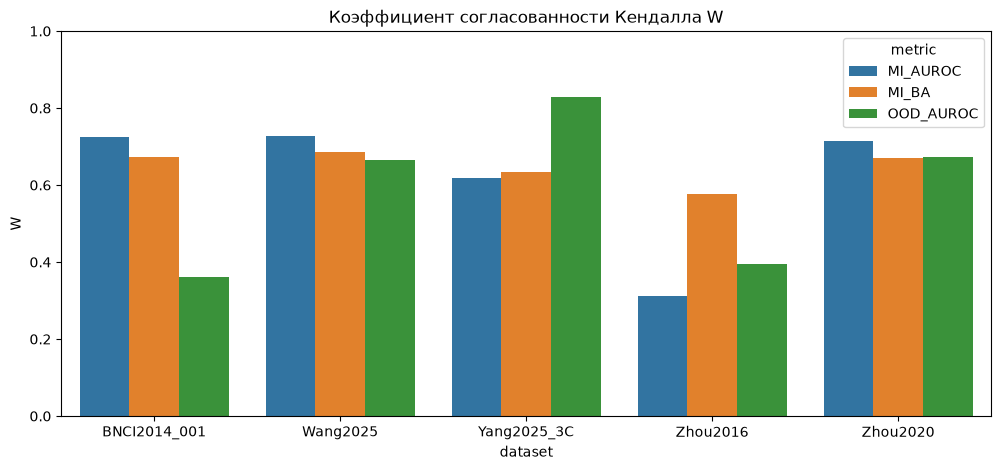

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.barplot(data=agreement, x="dataset", y="W", hue="metric", errorbar=None)
plt.title("Коэффициент согласованности Кендалла W")
plt.ylim(0, 1)
plt.show()

### По всем участникам

In [5]:
rows = []
for metric in [*MI_METRICS, "OOD_AUROC"]:
    rows.append({"metric": metric, "n": len(wide), "W": pg.friedman(wide[metric].reset_index(drop=True).T)["W"].iloc[0]})

agreement_all = pd.DataFrame(rows).set_index("metric")
display(agreement_all.round(4))


,n,W
metric,,
MI_BA,59,0.7312
MI_AUROC,59,0.7763
OOD_AUROC,59,0.6915


## Связь MI BA, MI AUROC с OOD AUROC

Проверяем, связаны ли средние ранги MI и OOD среди участников этого датасета.

Считается корреляция Спирмена.

Для каждого участника считается и усредняется его ранг в каждом методе, затем проверяется связь этих показателей.

Rho > 0 -- участники с более высокими результатами классификации MI обычно имеют более высокие результаты детекции OOD.

Для определения значимости используется перестановочный тест, затем применяется поправка Холма.


In [6]:
rows = []
for dataset, x in [*wide.groupby(level="dataset"), ("ALL datasets", wide)]:
    profiles = rank_profiles(x)
    ood = profiles["OOD_AUROC"].to_numpy()
    for metric in MI_METRICS:
        mi = profiles[metric].to_numpy()
        test = permutation_test((ood,), lambda y: spearmanr(mi, y).statistic, permutation_type="pairings", alternative="two-sided", n_resamples=9999, random_state=42)
        rows.append({"dataset": dataset, "metric": f"{metric} ~ OOD_AUROC", "n": len(x), "rho": test.statistic, "p_perm": test.pvalue})

association = pd.DataFrame(rows)
association["p_holm"] = pg.multicomp(association["p_perm"], method="holm")[1]
display(association.set_index(["metric", "dataset"]).round(4))


,,n,rho,p_perm,p_holm
metric,dataset,,,,
MI_BA ~ OOD_AUROC,BNCI2014_001,9,0.2000,0.6238,1.0000
MI_AUROC ~ OOD_AUROC,BNCI2014_001,9,0.3000,0.4370,1.0000
MI_BA ~ OOD_AUROC,Wang2025,15,0.7310,0.0040,0.0280
MI_AUROC ~ OOD_AUROC,Wang2025,15,0.7382,0.0034,0.0272
MI_BA ~ OOD_AUROC,Yang2025_3C,11,0.7818,0.0058,0.0348
MI_AUROC ~ OOD_AUROC,Yang2025_3C,11,0.7273,0.0138,0.0690
MI_BA ~ OOD_AUROC,Zhou2016,4,-0.2000,0.9167,1.0000
MI_AUROC ~ OOD_AUROC,Zhou2016,4,-0.2000,0.9167,1.0000
MI_BA ~ OOD_AUROC,Zhou2020,20,0.7334,0.0002,0.0024


### Корреляция Спирмена с учетом принадлежности к датасету

Неопределеность оценки при повторном выборе участников внутри каждого датасета (95% bootstrap интервалы)

In [7]:
ci = bootstrap_ci(wide)
adjusted = pd.DataFrame({"n": len(wide), "rho": adjusted_rho(wide), "CI_low": ci.low, "CI_high": ci.high, "p_perm": permutation_p(wide)}, index=pd.Index(MI_METRICS, name="metric"))
display(adjusted.round(4))


,n,rho,CI_low,CI_high,p_perm
metric,,,,,
MI_BA,59,0.6452,0.4487,0.7694,0.0001
MI_AUROC,59,0.6550,0.4662,0.7671,0.0001


Средняя корреляция MI–OOD, рассчитанная отдельно в каждом датасете, с весами по числу участников

In [8]:
weighted = pd.DataFrame({"rho": weighted_rho(wide), "p_perm": permutation_p(wide, statistic=weighted_rho)}, index=pd.Index(MI_METRICS, name="metric"))
weighted["p_holm"] = pg.multicomp(weighted["p_perm"], method="holm")[1]
display(weighted.round(4))

,rho,p_perm,p_holm
metric,,,
MI_BA,0.5972,0.0002,0.0004
MI_AUROC,0.5939,0.0002,0.0004


## Средние ранги по участникам

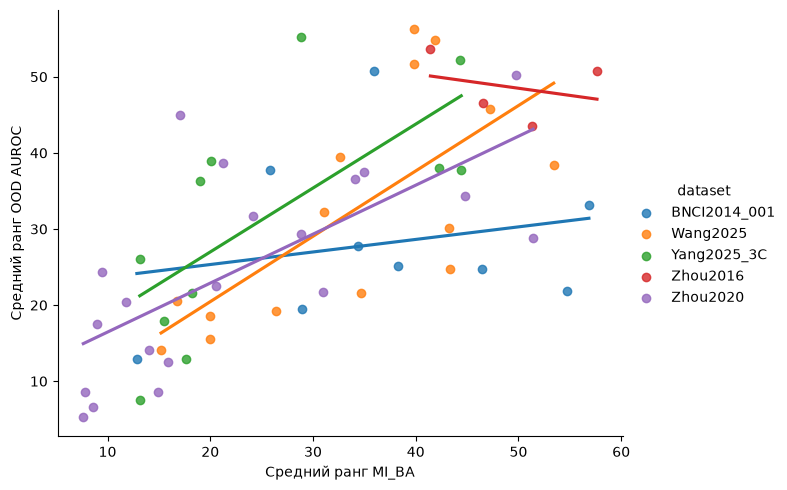

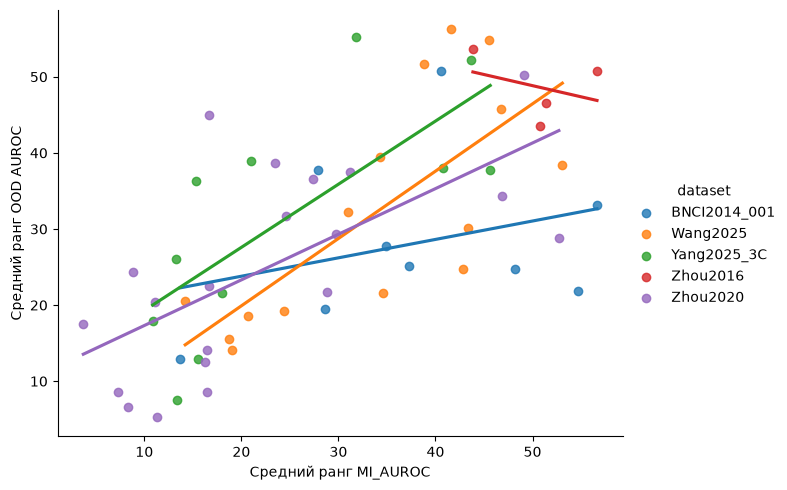

In [9]:
profiles = rank_profiles(wide).reset_index()
for metric in MI_METRICS:
    g = sns.lmplot(data=profiles, x=metric, y="OOD_AUROC", hue="dataset", ci=None, truncate=True, height=5, aspect=1.3)
    g.set_axis_labels(f"Средний ранг {metric}", "Средний ранг OOD AUROC")
    plt.show()

## Проверка устойчивости при исключении датасетов

In [10]:
rows = []
for kind, labels in [("dataset", wide.index.get_level_values("dataset").unique()), ("method", wide.columns.get_level_values("method").unique()), ("subject", wide.index)]:
    for label in labels:
        x = wide.drop(columns=label, level="method") if kind == "method" else wide.drop(index=label, level="dataset") if kind == "dataset" else wide.drop(index=[label])
        rows.append({"removed": kind, "label": str(label), **dict(zip(MI_METRICS, adjusted_rho(x)))})

sensitivity = pd.DataFrame(rows)
display(sensitivity.melt(id_vars=["removed", "label"], var_name="metric", value_name="rho").groupby(["removed", "metric"])["rho"].agg(["min", "max"]).round(3))
display(sensitivity[sensitivity["removed"].eq("dataset")].round(3))


min    max
removed metric                
dataset MI_AUROC  0.586  0.687
        MI_BA     0.532  0.683
method  MI_AUROC  0.613  0.682
        MI_BA     0.607  0.672
subject MI_AUROC  0.634  0.677
        MI_BA     0.622  0.669

,removed,label,MI_BA,MI_AUROC
0,dataset,BNCI2014_001,0.683,0.687
1,dataset,Wang2025,0.634,0.636
2,dataset,Yang2025_3C,0.641,0.635
3,dataset,Zhou2016,0.678,0.682
4,dataset,Zhou2020,0.532,0.586


## Результат проверки гипотез

In [11]:
agreement_overall = pd.DataFrame([{"metric": metric, "dataset": "ALL weighted", **overall_agreement(wide[metric])} for metric in [*MI_METRICS, "OOD_AUROC"]])
summary = pd.concat([agreement, agreement_overall], ignore_index=True).rename(columns={"W": "effect"}).assign(coefficient="W")
summary = pd.concat([summary, adjusted.reset_index().rename(columns={"rho": "effect"}).assign(dataset="ALL adjusted", coefficient="rho")], ignore_index=True)
summary["hypothesis"] = np.where(summary["coefficient"].eq("rho"), "H3: MI–OOD association", np.where(summary["metric"].eq("OOD_AUROC"), "H2: OOD agreement", "H1: MI agreement"))
summary["p_holm"] = pg.multicomp(summary["p_perm"], method="holm")[1]
summary["significant"] = summary["p_holm"] < 0.05
display(summary.loc[summary["dataset"].isin(["ALL weighted", "ALL adjusted"]), ["hypothesis", "metric", "dataset", "n", "coefficient", "effect", "p_perm", "p_holm", "significant"]].round(4))

,hypothesis,metric,dataset,n,coefficient,effect,p_perm,p_holm,significant
15,H1: MI agreement,MI_BA,ALL weighted,59,W,0.6613,0.0001,0.002,True
16,H1: MI agreement,MI_AUROC,ALL weighted,59,W,0.6740,0.0001,0.002,True
17,H2: OOD agreement,OOD_AUROC,ALL weighted,59,W,0.6340,0.0001,0.002,True
18,H3: MI–OOD association,MI_BA,ALL adjusted,59,rho,0.6452,0.0001,0.002,True
19,H3: MI–OOD association,MI_AUROC,ALL adjusted,59,rho,0.6550,0.0001,0.002,True


## Корреляции отдельных методов по участникам

Корреляции Спирмена. 

Столбцы и строки отсортированы по BA/AUROC методов.

### По всем участникам

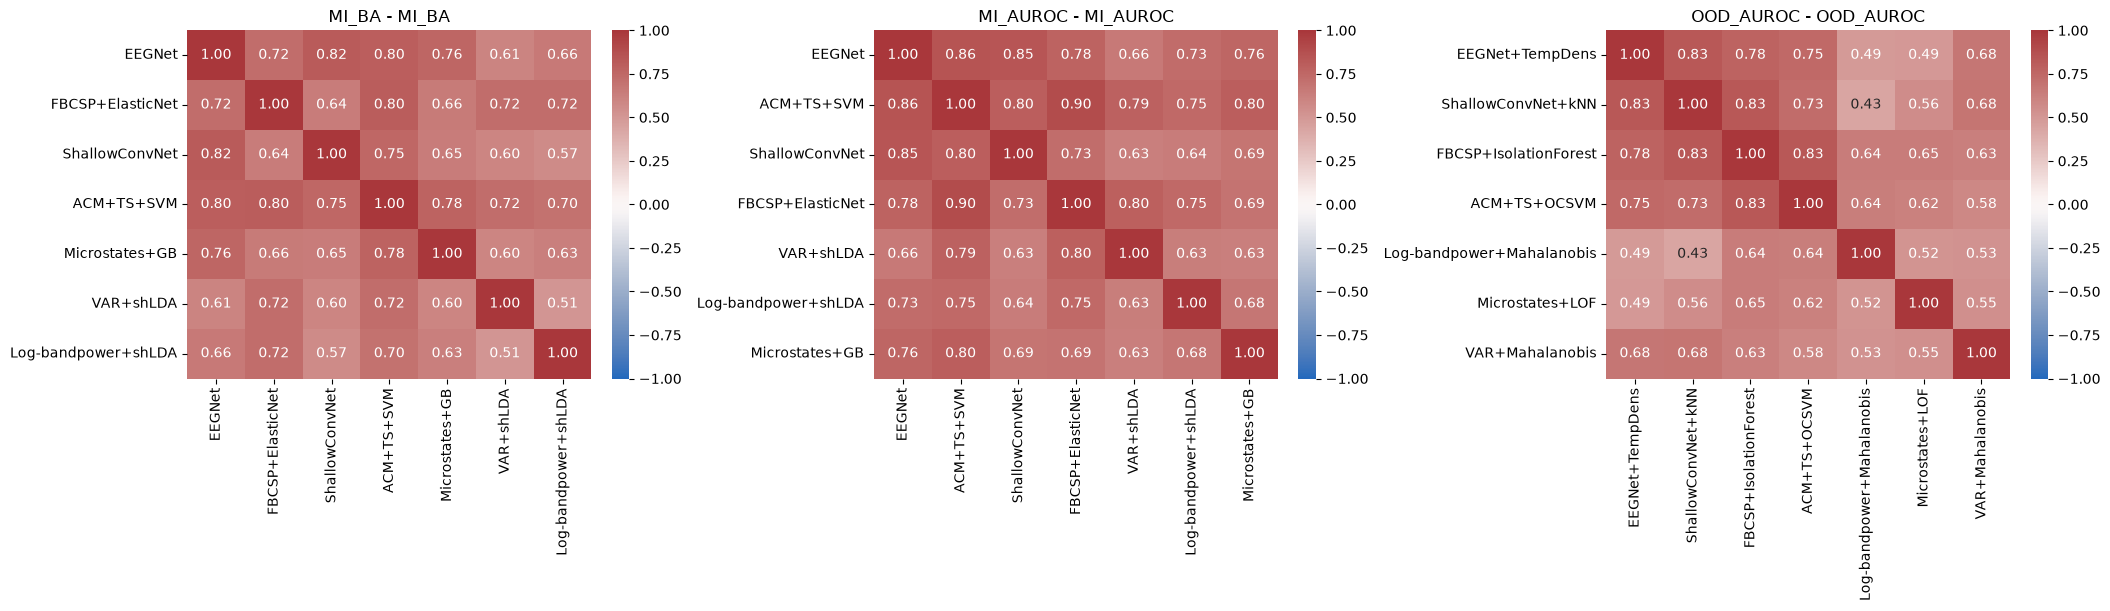

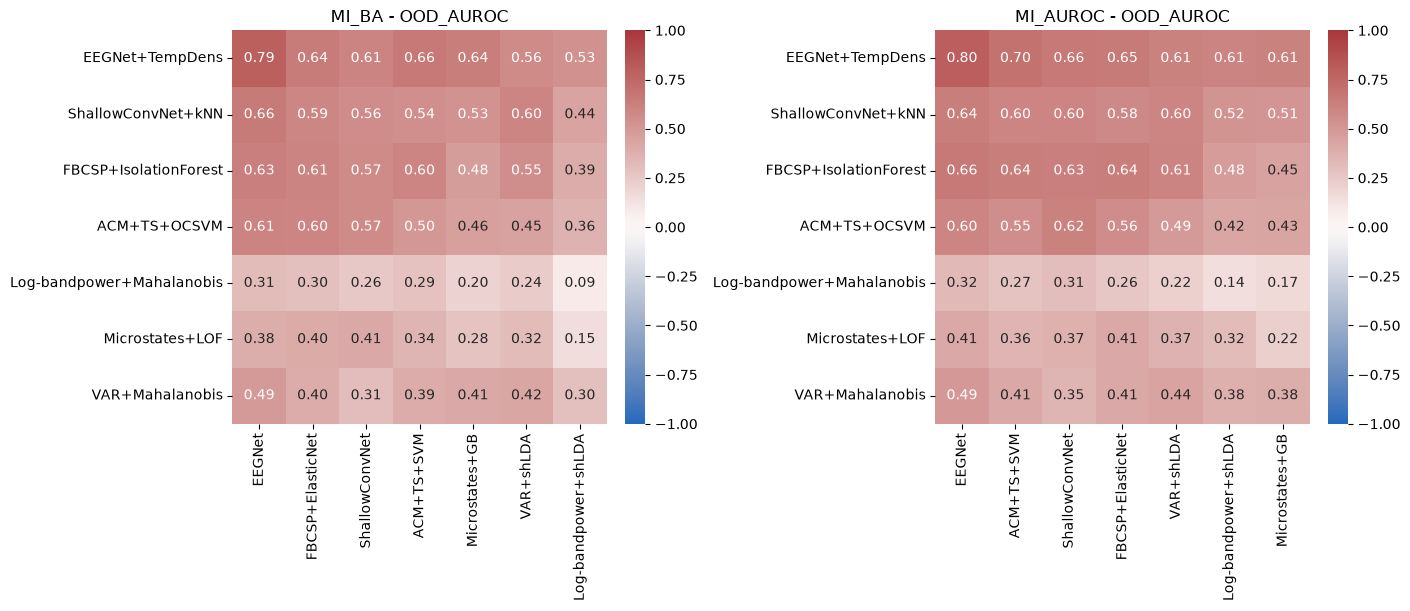

In [12]:
corr = wide.corr(method="spearman")

within = [(m, m) for m in [*MI_METRICS, "OOD_AUROC"]]
between = [("OOD_AUROC", m) for m in MI_METRICS]

for panels in [within, between]:
    fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 6), layout="constrained")
    for ax, (a, b) in zip(axes, panels):
        matrix = corr.xs(a).xs(b, axis=1)
        matrix = matrix.reindex(index=wide[a].mean().sort_values(ascending=False).index, columns=wide[b].mean().sort_values(ascending=False).index)
        sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0)
        ax.set(title=f"{b} - {a}", xlabel="", ylabel="")
    plt.show()

### Взвешенное среднее по датасетам

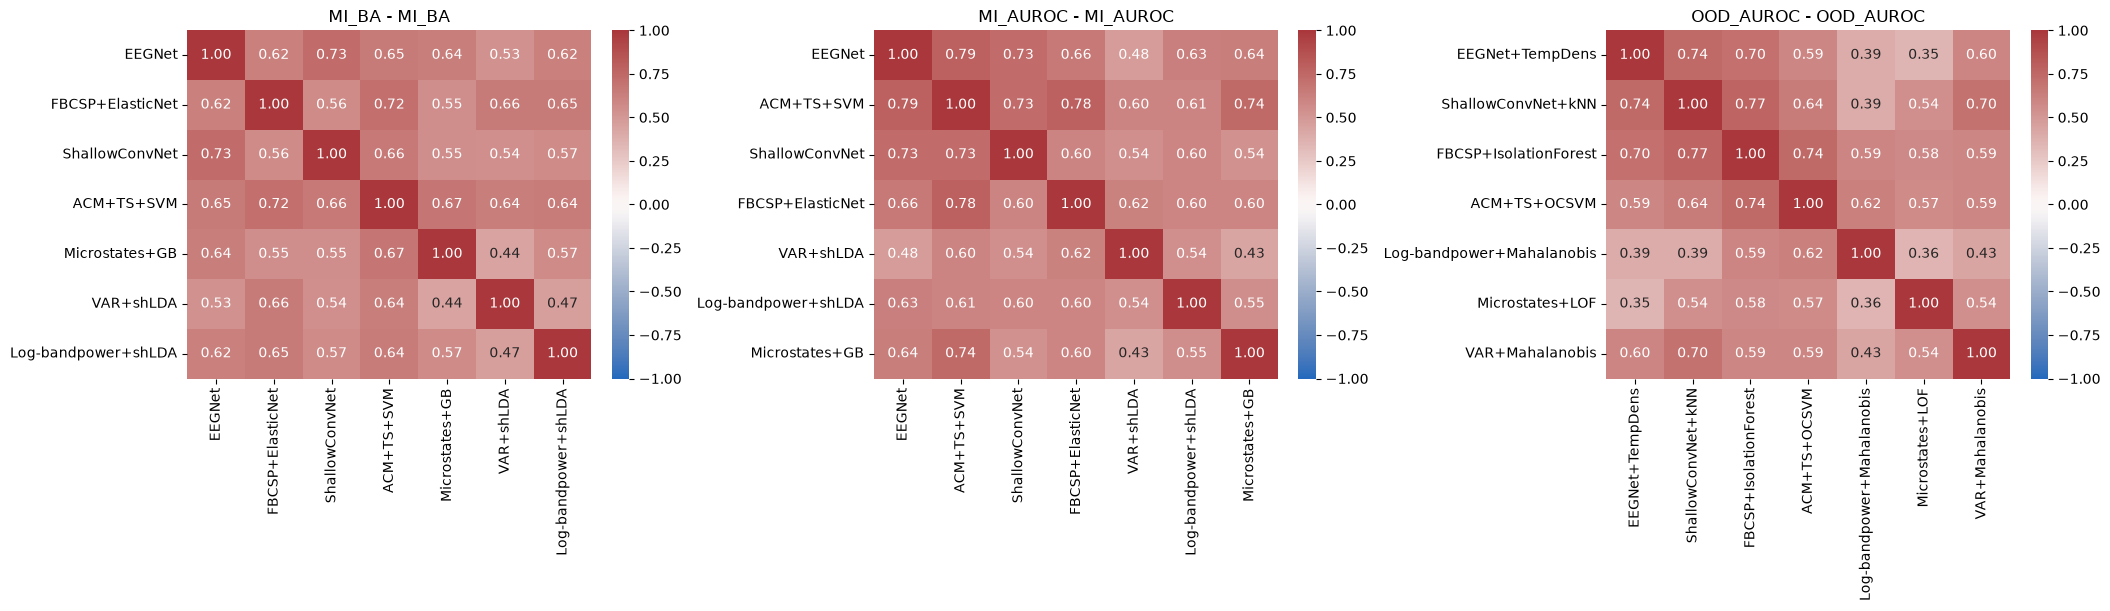

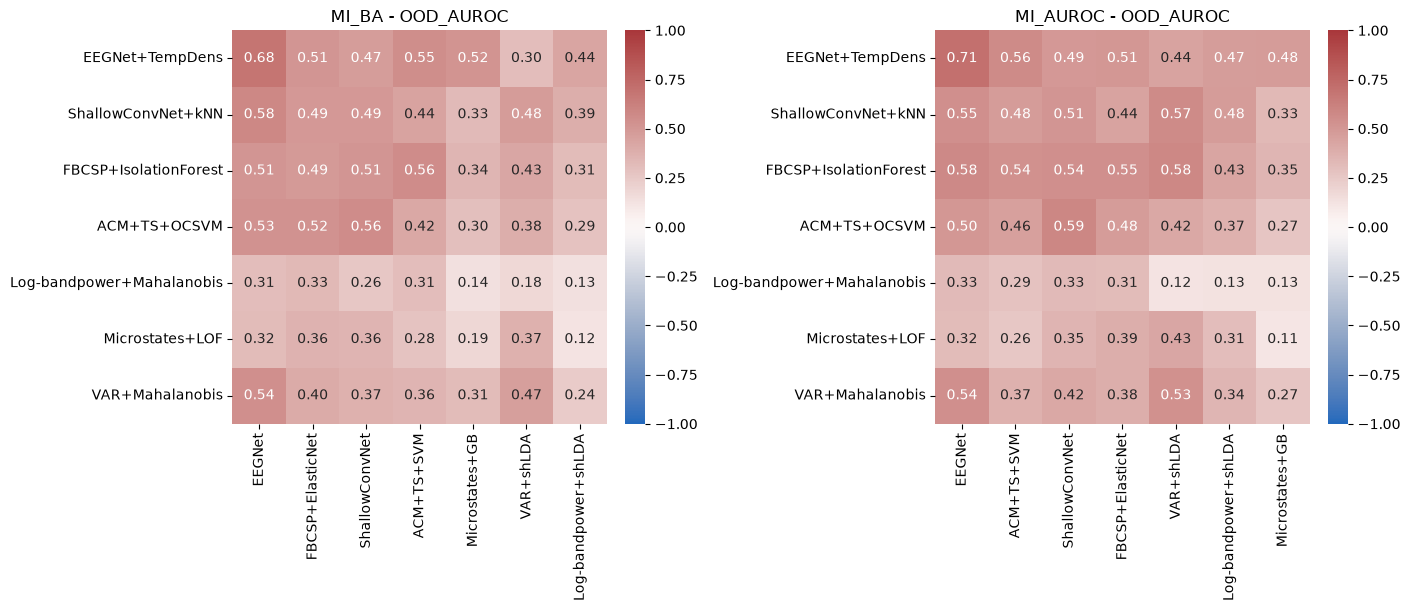

In [13]:
parts = [x for _, x in wide.groupby(level="dataset") if len(x) >= 3]
corr_within = pd.DataFrame(np.average([x.corr(method="spearman").to_numpy() for x in parts], axis=0, weights=[len(x) for x in parts]), index=wide.columns, columns=wide.columns)

within = [(m, m) for m in [*MI_METRICS, "OOD_AUROC"]]
between = [("OOD_AUROC", m) for m in MI_METRICS]

for panels in [within, between]:
    fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 6), layout="constrained")
    for ax, (a, b) in zip(axes, panels):
        matrix = corr_within.xs(a).xs(b, axis=1)
        matrix = matrix.reindex(index=wide[a].mean().sort_values(ascending=False).index, columns=wide[b].mean().sort_values(ascending=False).index)
        sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0)
        ax.set(title=f"{b} - {a}", xlabel="", ylabel="")
    plt.show()


Корреляции между методами

In [14]:
rows = []
for metric in MI_METRICS:
    r = corr_within.xs("OOD_AUROC").xs(metric, axis=1).to_numpy().ravel()
    rows.append({"metric": metric, "median_rho": np.median(r), "min_rho": r.min(), "max_rho": r.max(), "positive_pairs": int((r > 0).sum()), "pairs": r.size})
display(pd.DataFrame(rows).set_index("metric").round(3))

,median_rho,min_rho,max_rho,positive_pairs,pairs
metric,,,,,
MI_BA,0.385,0.121,0.682,49,49
MI_AUROC,0.430,0.114,0.705,49,49


## Результаты по участникам

Строки упорядочены по медиане MI BA, столбцы упорядочены по BA/AUROC.

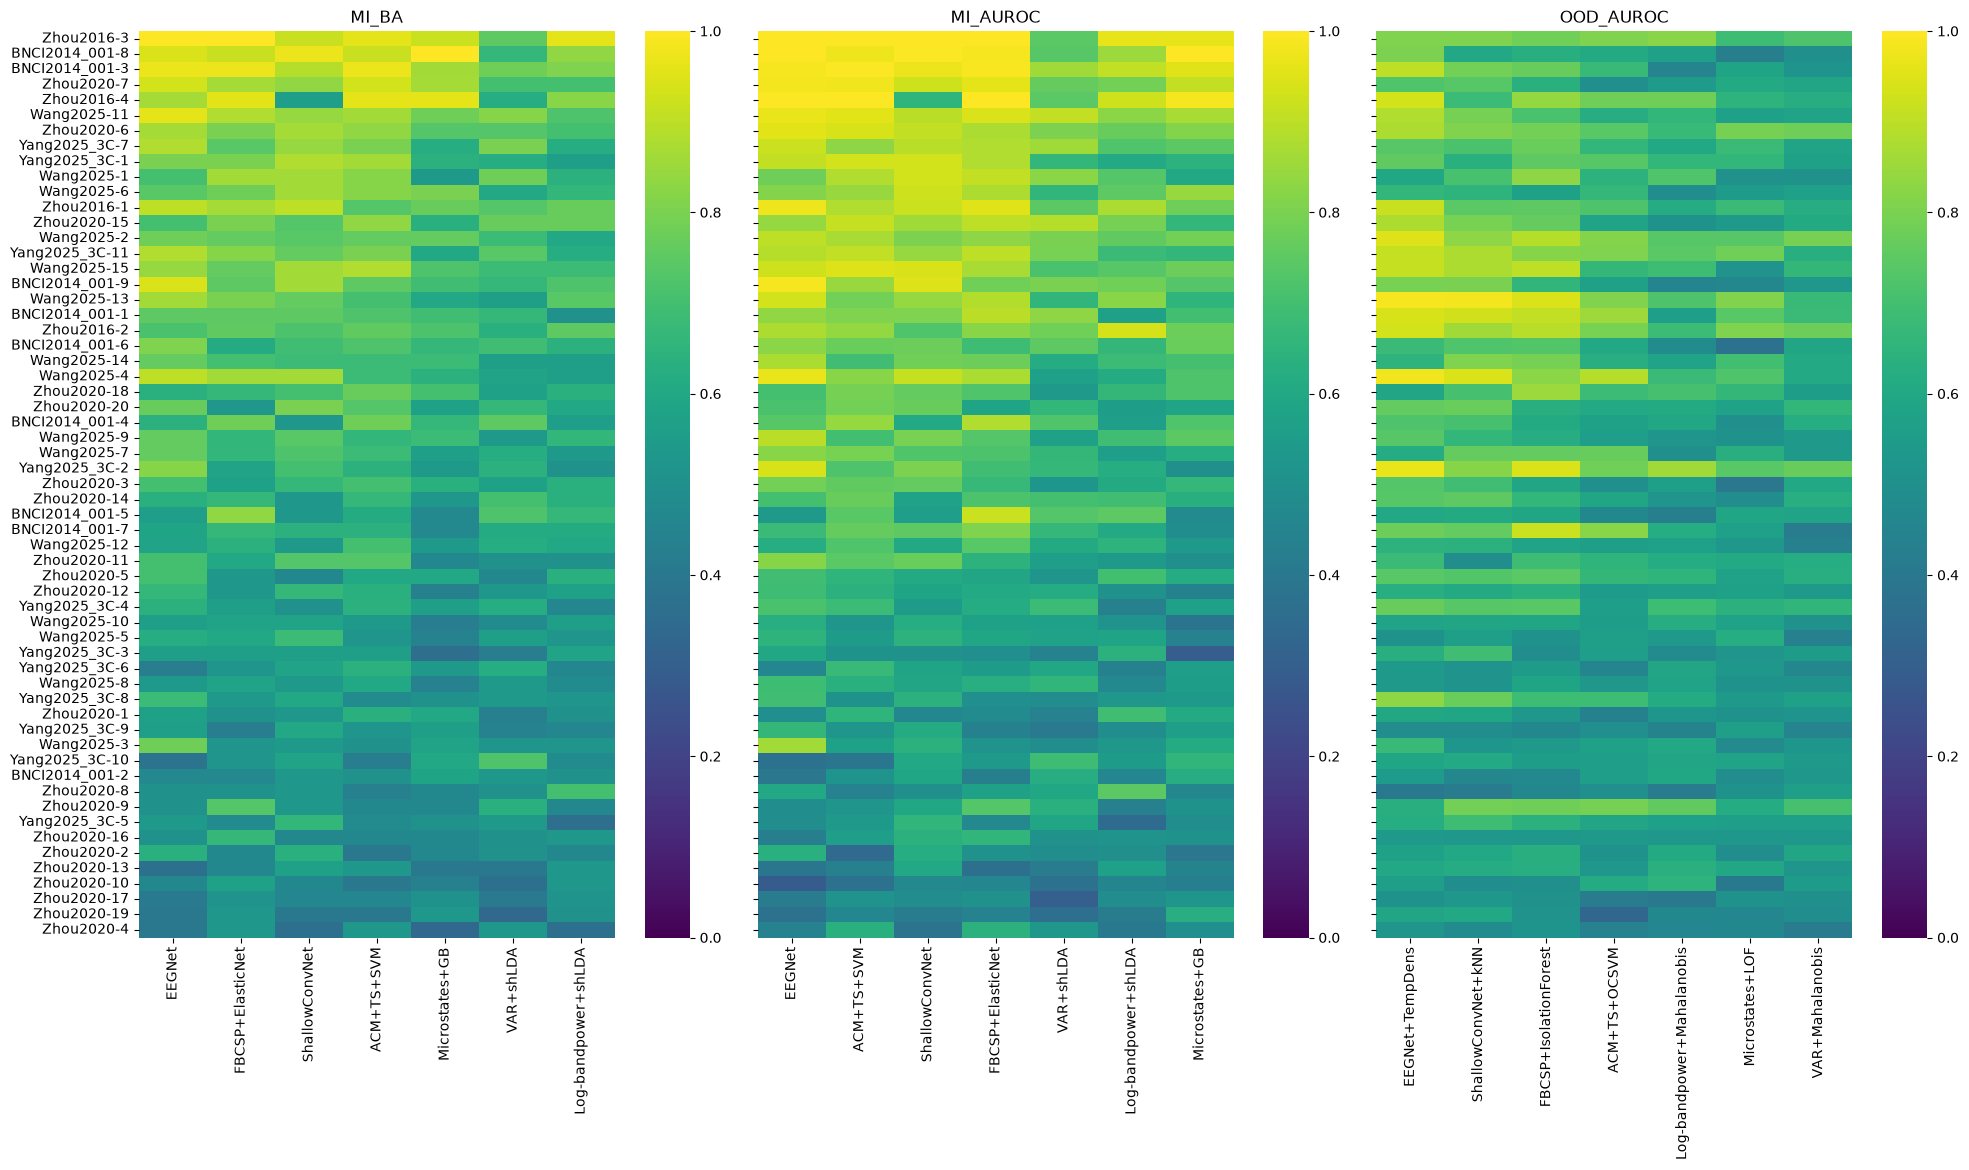

In [15]:
ordered = wide.loc[wide["MI_BA"].median(axis=1).sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 3, figsize=(20, max(6, len(wide) * .2)), sharey=True)
for ax, metric in zip(axes, ["MI_BA", "MI_AUROC", "OOD_AUROC"]):
    t = ordered[metric]
    t = t.loc[:, t.mean().sort_values(ascending=False).index]
    sns.heatmap(t, ax=ax, cmap="viridis", vmin=0, vmax=1, yticklabels=True)
    ax.set(title=metric, xlabel="", ylabel="")
    ax.tick_params(axis="y", labelleft=ax is axes[0])
plt.tight_layout()
plt.show()

## Распределения всех сочетаний методов внутри участников

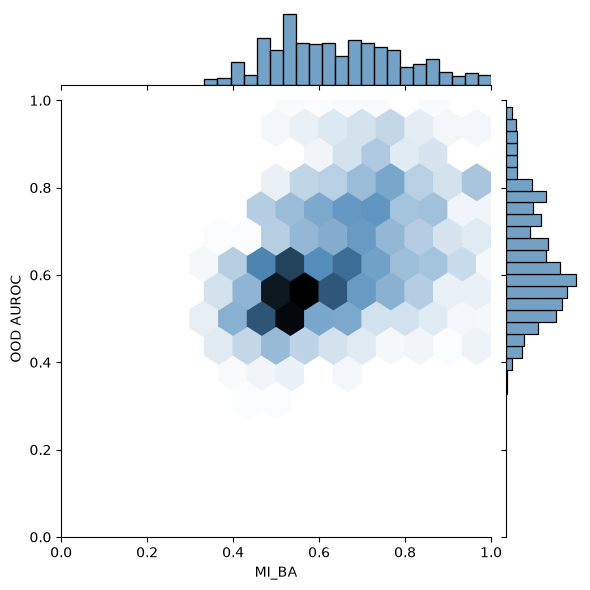

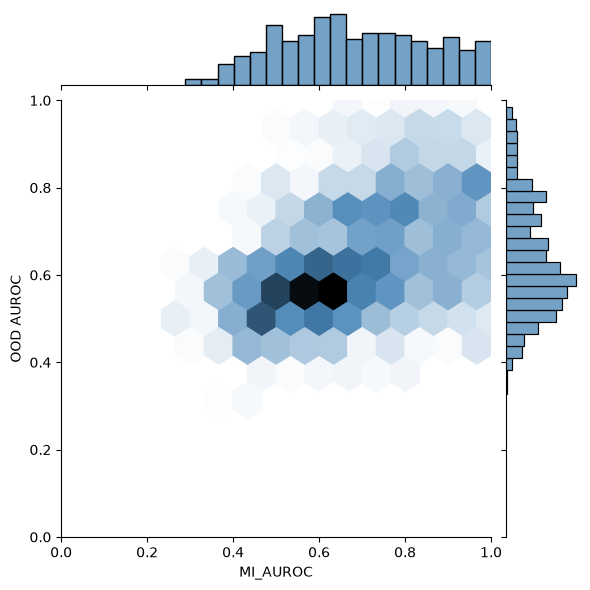

In [16]:
ood_long = wide["OOD_AUROC"].stack().rename("OOD").reset_index()
for metric in MI_METRICS:
    pairs = wide[metric].stack().rename("MI").reset_index().merge(
        ood_long, on=["dataset", "subject"])
    g = sns.jointplot(data=pairs, x="MI", y="OOD", kind="hex", height=6,
                      xlim=(0, 1), ylim=(0, 1), gridsize=15,
                      extent=(0, 1, 0, 1), mincnt=1, color="steelblue")
    g.set_axis_labels(metric, "OOD AUROC")
    plt.show()